# Telecom Customer Churn Analysis

**Goal:** Find out which customers are most likely to leave a telecom company, and why.

**Data:** 7,043 customers from Kaggle ([link](https://www.kaggle.com/datasets/alipakzad/telecom-customer-churn))

**Tools:** Python, pandas, matplotlib

In [1]:
import kagglehub
import os
import pandas as pd

## Loading the data
Downloaded the dataset directly from Kaggle using the kagglehub library and loaded it into a pandas DataFrame.

In [2]:
path = kagglehub.dataset_download("alipakzad/telecom-customer-churn")
df = pd.read_csv(os.path.join(path, "IT_customer_churn.csv"))
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## Cleaning the data
TotalCharges was stored as text because 11 cells were blank. All 11 were new customers (tenure = 0) who hadn't been billed yet, so the blanks were filled with 0.

In [3]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [4]:
print("Size of table:", df.shape)
print("Missing TotalCharges:", df["TotalCharges"].isna().sum())
print("TotalCharges data type:", df["TotalCharges"].dtype)

Size of table: (7043, 20)
Missing TotalCharges: 0
TotalCharges data type: float64


##  Overall churn rate
26.5% of customers left the company, more than 1 in 4.

In [5]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [6]:
df["Churn"].value_counts(normalize=True) * 100

Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64

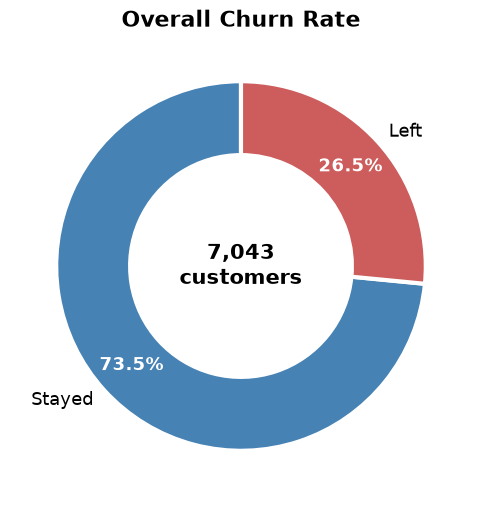

In [19]:
churn_counts = df["Churn"].value_counts()

fig, ax = plt.subplots(figsize=(6, 6))

wedges, texts, autotexts = ax.pie(
    churn_counts,
    labels=churn_counts.index.map({"No": "Stayed", "Yes": "Left"}),
    autopct="%.1f%%",
    startangle=90,
    colors=["steelblue", "indianred"],
    pctdistance=0.8,
    labeldistance=1.08,
    wedgeprops={"width": 0.4, "edgecolor": "white", "linewidth": 3},
    textprops={"fontsize": 13})

for t in autotexts:
    t.set_color("white")
    t.set_fontweight("bold")

ax.text(0, 0, "7,043\ncustomers", ha="center", va="center", fontsize=15, fontweight="bold")
ax.set_title("Overall Churn Rate", fontsize=16, fontweight="bold")
plt.savefig("churn_donut.png", dpi=150, bbox_inches="tight")
plt.show()

In [17]:
lost_revenue = df[df["Churn"] == "Yes"]["MonthlyCharges"].sum()
total_revenue = df["MonthlyCharges"].sum()

print(f"Monthly revenue lost: {lost_revenue:,.2f}")
print("Share of total monthly revenue:", round(lost_revenue / total_revenue * 100, 1), "%")
print(f"Yearly revenue lost: {lost_revenue * 12:,.2f}")


Monthly revenue lost: 139,130.85
Share of total monthly revenue: 30.5 %
Yearly revenue lost: 1,669,570.20


## Churn by contract type
customers on month-to-month contracts are the most likely to leave, with churn rate of 42.7% compared to 6.8% of other contract types

In [7]:
pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).round(1)

Churn,No,Yes
Contract,,
Month-to-month,57.3,42.7
One year,88.7,11.3
Two year,97.2,2.8


## %Churn by contract type
customers on month-to-month contracts are the most likely to leave, with churn rate of 42.7% compared to 6.8% of other contract types

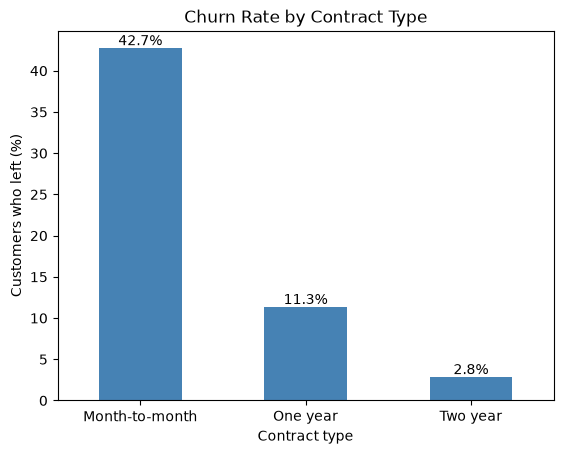

In [20]:
import matplotlib.pyplot as plt

churn_by_contract = pd.crosstab(df["Contract"], df["Churn"], normalize="index").mul(100).round(1)

ax = churn_by_contract["Yes"].plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Customers who left (%)")
plt.xlabel("Contract type")
plt.xticks(rotation=0)
plt.savefig("churn_by_contract.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
df.to_csv("telecom_churn_clean.csv", index=False)
print("Saved!")

Saved!


## Tenure and monthly charges
Customers who left paid more each month, $74.40 on average compared with $61.30 for those who stayed, a difference of about $13

In [9]:
df.groupby("Churn")[["tenure", "MonthlyCharges"]].mean().round(1)

,tenure,MonthlyCharges
Churn,,
No,37.6,61.3
Yes,18.0,74.4


## Churn by tenure group
New customers are the most likely to leave: 47.4% churned in their first year, and the churn rate falls steadily the longer customers stay, down to 9.5% for those with 4–6 years.

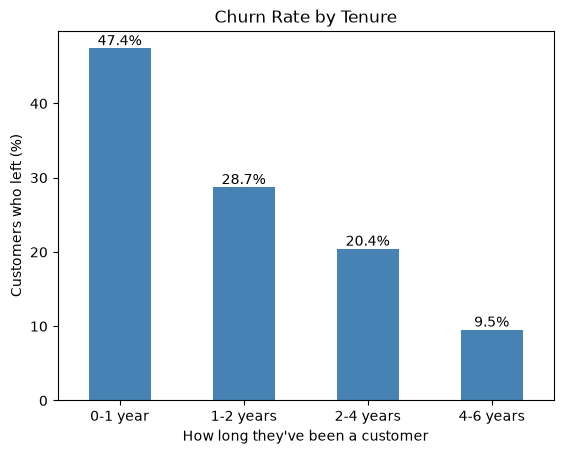

In [21]:
df["TenureGroup"] = pd.cut(df["tenure"],
                           bins=[-1, 12, 24, 48, 72],
                           labels=["0-1 year", "1-2 years", "2-4 years", "4-6 years"])

churn_by_tenure = pd.crosstab(df["TenureGroup"], df["Churn"], normalize="index").mul(100).round(1)

ax = churn_by_tenure["Yes"].plot(kind="bar", color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%")
plt.title("Churn Rate by Tenure")
plt.ylabel("Customers who left (%)")
plt.xlabel("How long they've been a customer")
plt.xticks(rotation=0)
plt.savefig("churn_by_tenure.png", dpi=150, bbox_inches="tight")
plt.show()

In [11]:
long_contract = df[df["Contract"] != "Month-to-month"]

long_contract["Churn"].value_counts(normalize=True).mul(100).round(1)

Churn
No     93.2
Yes     6.8
Name: proportion, dtype: float64

## Conclusion

**Key findings:**
- Customers on month-to-month contracts are the most likely to leave, with a churn rate of 42.7% compared with 6.8% for customers on one- or two-year contracts.
- Customers who left paid more each month: 74.40 on average, compared with 61.30 for those who stayed.
- New customers are the most likely to leave: 47.4% churned in their first year, falling to 9.5% for customers of 4–6 years.
- Customers who left took away 139,130.85 in monthly revenue (30.5% of the total), which could add up to about 1.67 million in lost revenue per year.

**Recommendation:**
The company should focus on keeping customers through their first year, for example by offering discounted rates for the first few months and a discount for switching to a one-year contract.